# Robustness of the logical S gate for [[4,1,2]] code


In this notebook, we construct a circuit to check the robustness of a logical S gate in for the [[4,1,2]] code. 

The code has the following stabilizer generators:

\begin{equation}
    \mathcal{S} = \langle X_0X_1X_2X_3, Z_0Z_1I_2I_3, I_0I_1Z_2Z_3 \rangle,
\end{equation}

And its logical operators are:
\begin{align}
    & \bar{X} = X_0X_1I_2I_3, \\
    & \bar{Z} = I_0Z_1Z_2I_3.
\end{align}

Then, the logical states of the code can be, for exmaple, denoted as:
\begin{align}
    & \bar{\ket{0}} = \frac{1}{\sqrt{2}}(\ket{0000}+ \ket{1111})\\
    & \bar{\ket{1}} = \frac{1}{\sqrt{2}}(\ket{1100}+ \ket{0011})
\end{align}

We know that the logical S gate is $\bar{S} = \bar{\sqrt{Z}}$. Therefore, the derivation yields:

\begin{equation}
    \bar{S} = I_0 (S_1\otimes S_2)CZ_{(1,2)} I_3,
\end{equation}
whare $S_i$ is the single-qubit S gate on the $i$-th qubit and $CZ_{(i,j)}$ is the controlled Z gate on the qubits $i$ and $j$.

In [1]:
import stim

# 1. Robustness with no encoding 

We are first going to familiarize ourselves with the stim library. We first construct the circuit without any encoding, to check the robustness of the S gate via Bell basis measurement.

In [3]:
#Defining the circuit to check the robustness of S without encoding 

circuit = stim.Circuit()

#Creation of Bell pair
circuit.append_operation("H",0)
circuit.append("CNOT", [0, 1])
circuit.append_operation("S", [0,1])
circuit.append("CNOT", [0, 1])
circuit.append_operation("H",0)
circuit.append("M", [0, 1])

print(repr(circuit))


stim.Circuit('''
    H 0
    CX 0 1
    S 0 1
    CX 0 1
    H 0
    M 0 1
''')


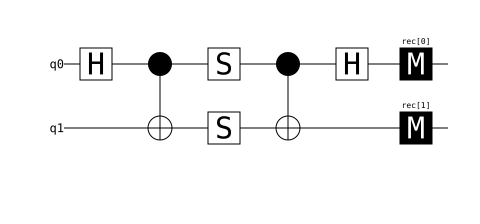

In [7]:
#Checking how the circuit looks like

circuit.diagram('timeline-svg')

In [ ]:
#Checking robustness without encoding

sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]
 [ True False]]


## Explanation

The Bell states and the final measurement outcomes they correspond to are:

\begin{align}
    &\ket{\Phi^+} = \frac{1}{\sqrt{2}}(\ket{00} + \ket{11}) \rightarrow 00,\\ 
    &\ket{\Phi^-} = \frac{1}{\sqrt{2}}(\ket{00} - \ket{11}) \rightarrow 10,\\
    &\ket{\Psi^+} = \frac{1}{\sqrt{2}}(\ket{01} + \ket{10}) \rightarrow 01,\\
    &\ket{\Psi^-} = \frac{1}{\sqrt{2}}(\ket{01} - \ket{10}) \rightarrow 11.
\end{align}

At the beginnig, we generate the $\ket{\Phi^+}$ Bell state. The application of S gates on each qubit transforms the state to $\ket{\Phi^-}$, giving us the outcomes 1,0 in the measurement. The result is the same in every trial, because we do not have encoding, decoding and errors. 

In conclusion, when we will be checking for robstness (and fidelity) in the final circuit with logical S, we will be intererested in the percentage of trials where we obtain the $\ket{\Phi^-}$ at the end.

# 2. Encoder and Decoder 

We write down a circuit to encode a state with [[4,1,2]] code and subsequently, to decode it.

stim.Circuit('''
    H 2
    CX 2 0 0 1 2 3
    M 0 1 2 3
''')


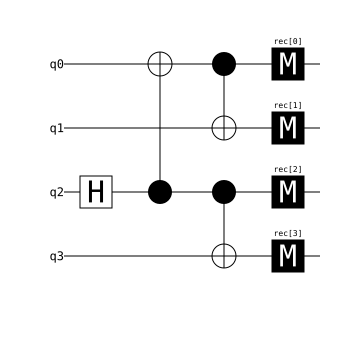

In [15]:
#Encoder
circuit = stim.Circuit()
circuit.append_operation("H",2)
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])
circuit.append("M", [0, 1,2,3])



print(repr(circuit))
circuit.diagram('timeline-svg')

In [14]:
#Sampling the circuit with encoding

sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[False False  True  True]
 [ True  True False False]
 [ True  True False False]
 [False False  True  True]
 [False False  True  True]
 [False False  True  True]
 [ True  True False False]
 [False False  True  True]
 [ True  True False False]
 [False False  True  True]]


stim.Circuit('''
    H 2
    CX 2 0 0 1 2 3 2 3 0 1 2 0
    H 2
    M 0 1 2 3
''')


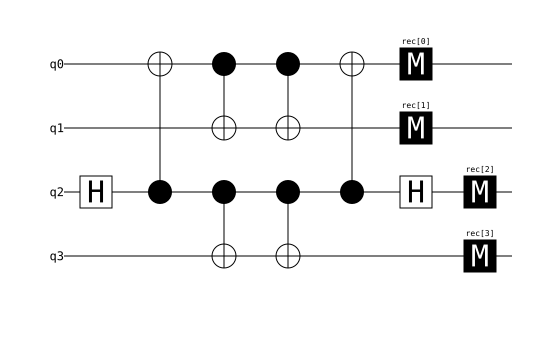

In [ ]:
#Encoder + Decoder (encoder in reversed order)

circuit = stim.Circuit()

#Encoder
circuit.append_operation("H",2)
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])

#Decoder
circuit.append("CNOT", [2, 3])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 0])  
circuit.append_operation("H",2)

#Measurement
circuit.append("M", [0, 1,2,3])

print(repr(circuit))
circuit.diagram('timeline-svg')

In [24]:
#Sampling the circuit with encoding and decoding

sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]
 [False False False False]]


# 3. Encoder, logical S gate, decoder

Now, we add a logical S gate in [[4,1,2]] code between encoder and decoder. We are going to add one more qubit and check at the end like in Section 1. 

stim.Circuit('''
    H 0
    CX 0 4
    H 2
    CX 2 0 0 1 2 3
    S 1 2
    CZ 1 2
    S_DAG 4
    CX 2 3 0 1 2 0
    H 2
    CX 0 4
    H 0
    M 0 4
''')


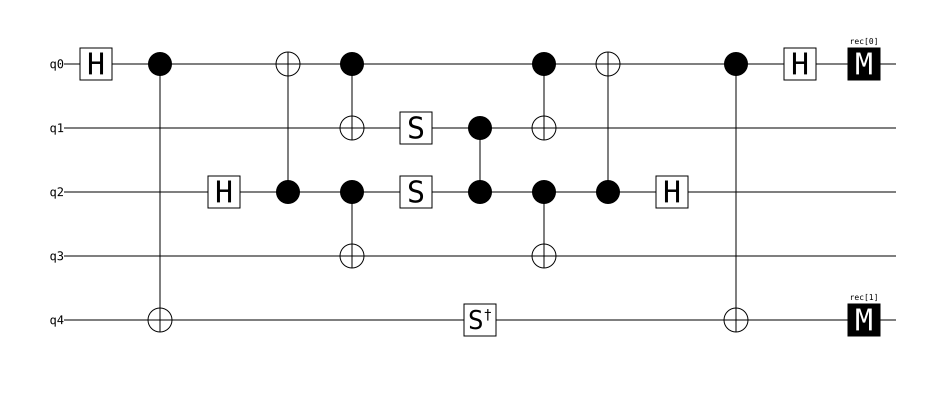

In [57]:
circuit = stim.Circuit()

#Creation of Bell pair between the logical qubit and the ancilla qubit
circuit.append_operation("H",0)
circuit.append("CNOT", [0, 4])


#Encoder
circuit.append_operation("H",2)
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])

#Logical S gate
circuit.append_operation("S", [1,2])
circuit.append("CZ", [1, 2])

#S_dag gate on the ancilla qubit
circuit.append_operation("S_DAG", [4])

#Decoder
circuit.append("CNOT", [2, 3])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 0])  
circuit.append_operation("H",2)

#Measurement of the logical qubit and the ancilla qubit in the Bell basis
circuit.append("CNOT", [0, 4])
circuit.append_operation("H",0)
circuit.append("M", [0, 4])

print(repr(circuit))
circuit.diagram('timeline-svg')

In [58]:
#Checking if the simulation yields the same results as the circuit without encoding

sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]]


At the beginnig, we generate the $\ket{\Phi^+}$ Bell state. The application of $S$ and $S^\dag$ gates on the logical and ancilla qubit keeps the state as $\ket{\Phi^+}$, giving us the outcomes 0,0 in the measurement (we implemented the dager to have 0,0, instead of 1,0 outcomse). Thus, our encoder and decoder should work correctly. 

# 4. Including errors and stabilizer measurements

Now, we will add the stabilizer checks during the decoding stage. We will also add pauli errors on each gate that the logical S is composed of.

In [70]:
#Error rate 

p = 0.5

stim.Circuit('''
    H 0
    CX 0 4
    H 2
    CX 2 0 0 1 2 3
    S 1 2
    DEPOLARIZE1(0) 1 2
    CZ 1 2
    DEPOLARIZE2(0) 1 2
    S_DAG 4
    CX 2 3 0 1 2 0
    H 2
    CX 0 4
    H 0
    M 0 4
''')


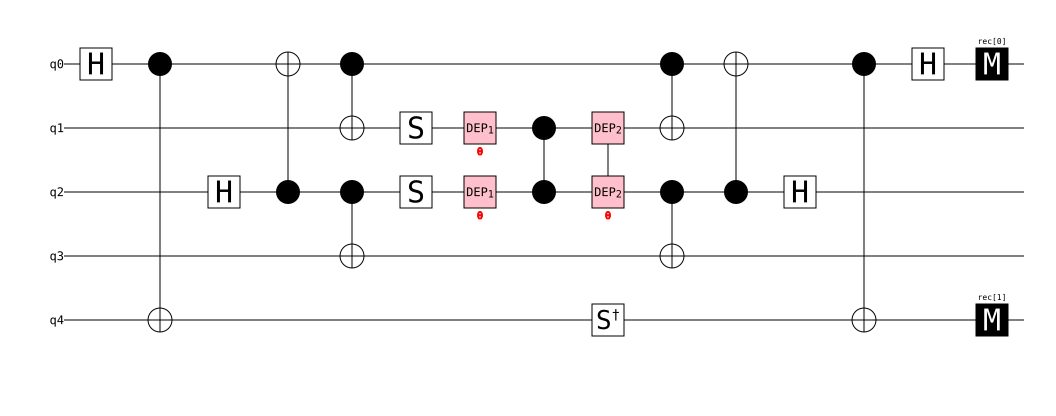

In [59]:
circuit = stim.Circuit()

#Creation of Bell pair between the logical qubit and the ancilla qubit
circuit.append_operation("H",0)
circuit.append("CNOT", [0, 4])


#Encoder
circuit.append_operation("H",2)
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])

#Logical S gate with errors
circuit.append_operation("S", [1,2])
circuit.append("DEPOLARIZE1", [1, 2], p)
circuit.append("CZ", [1, 2])
circuit.append("DEPOLARIZE2", [1, 2], p)

#S_dag gate on the ancilla qubit
circuit.append_operation("S_DAG", [4])

#Decoder
circuit.append("CNOT", [2, 3])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 0])  
circuit.append_operation("H",2)

#Measurement of the logical qubit and the ancilla qubit in the Bell basis
circuit.append("CNOT", [0, 4])
circuit.append_operation("H",0)
circuit.append("M", [0, 4])

print(repr(circuit))
circuit.diagram('timeline-svg')

In [61]:
#Sampling the circuit wuith encoding and decoding with errors
sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]
 [False False]]


Now, we obtain different outputs because of the errors.

stim.Circuit('''
    H 0
    CX 0 6
    H 2
    CX 2 0 0 1 2 3
    S 1 2
    DEPOLARIZE1(0) 1 2
    CZ 1 2
    DEPOLARIZE2(0) 1 2
    S_DAG 6
    CX 2 3 0 1 2 0
    H 2 4
    CX 4 5 0 4
    H 0
    M 0 4
    CX rec[-1] 5
    CZ rec[-2] 5
    CX 5 6
    H 5
    M 5 6
''')


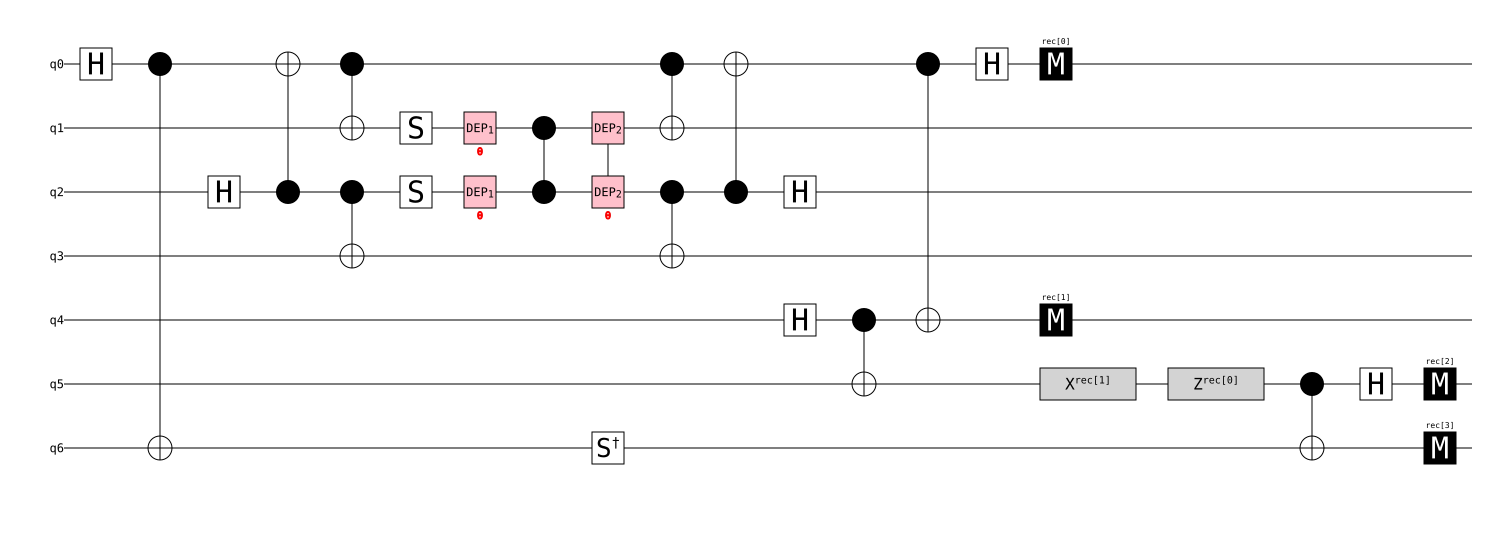

In [62]:
#Adding Teleportation to photonic qubit 

circuit = stim.Circuit()

#Creation of Bell pair between the logical qubit and the ancilla qubit
circuit.append_operation("H",0)
circuit.append("CNOT", [0, 6])


#Encoder
circuit.append_operation("H",2)
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])

#Logical S gate with errors
circuit.append_operation("S", [1,2])
circuit.append("DEPOLARIZE1", [1, 2], p)
circuit.append("CZ", [1, 2])
circuit.append("DEPOLARIZE2", [1, 2], p)

#S_dag gate on the ancilla qubit
circuit.append_operation("S_DAG", [6])

#Decoder
circuit.append("CNOT", [2, 3])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 0])  
circuit.append_operation("H",2)

#Adding another entangled qubit (creating Bell pair) to teleport the logical qubit to and measuring the stabilizers of the 4-qubit code
circuit.append_operation("H", [4])
circuit.append("CNOT", [4, 5]) 

#Teleportation of the logical qubit to the new qubit - bell basis measurement
circuit.append("CNOT", [0, 4])
circuit.append_operation("H",0)
circuit.append("M", [0, 4])
# Apply X to qubit 5 if the latest measurement is 1.
circuit.append("CX", [stim.target_rec(-1), 5])

# Apply Z to qubit 5 if the second-latest measurement is 1.
circuit.append("CZ", [stim.target_rec(-2), 5])

#Measurement of the logical qubit and the ancilla qubit in the Bell basis
circuit.append("CNOT", [5, 6])
circuit.append_operation("H", [5])
circuit.append("M", [5, 6])


print(repr(circuit))
circuit.diagram('timeline-svg')



In [64]:
#Sampling the circuit wuith encoding and decoding with errors
sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[ True  True False False]
 [False False False False]
 [False False False False]
 [ True  True False False]
 [ True  True False False]
 [ True  True False False]
 [ True False False False]
 [ True False False False]
 [False  True False False]
 [ True  True False False]]


## Explanation 

We successfully teleported our state out of the decoder on the qubit 5 (representing a photon). The first two measurements are from the teleportation protocol and they can yield different results, but at the end, we successfully teleport the state to the photon, yielding the same resukts in the final Bell basis measurement.

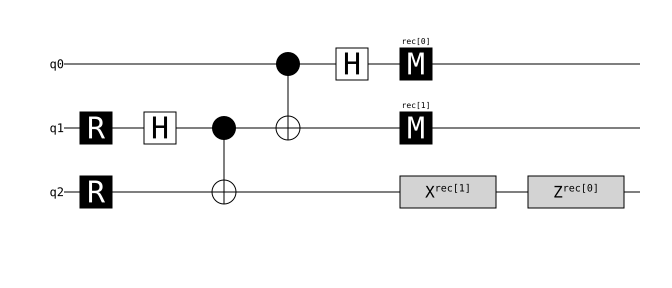

In [65]:
#Quantum teleportation circuit for reference

circuit = stim.Circuit("""
    # Qubit 0 holds the input state.
    # Initialize the Bell-pair qubits.
    R 1 2

    # Shared Bell pair.
    H 1
    CX 1 2

    # Alice's Bell-basis measurement.
    CX 0 1
    H 0
    M 0 1

    # Bob's corrections.
    CX rec[-1] 2
    CZ rec[-2] 2
""")

circuit.diagram('timeline-svg')

## Adding stabilizer measurements



stim.Circuit('''
    H 0
    CX 0 6
    H 2
    CX 2 0 0 1 2 3
    S 1 2
    DEPOLARIZE1(0.5) 1 2
    CZ 1 2
    DEPOLARIZE2(0.5) 1 2
    S_DAG 6
    CX 2 3 0 1 2 0
    H 2
    M 1 2 3
    H 4
    CX 4 5 0 4
    H 0
    M 0 4
    CX rec[-1] 5
    CZ rec[-2] 5
    CX 5 6
    H 5
    M 5 6
''')


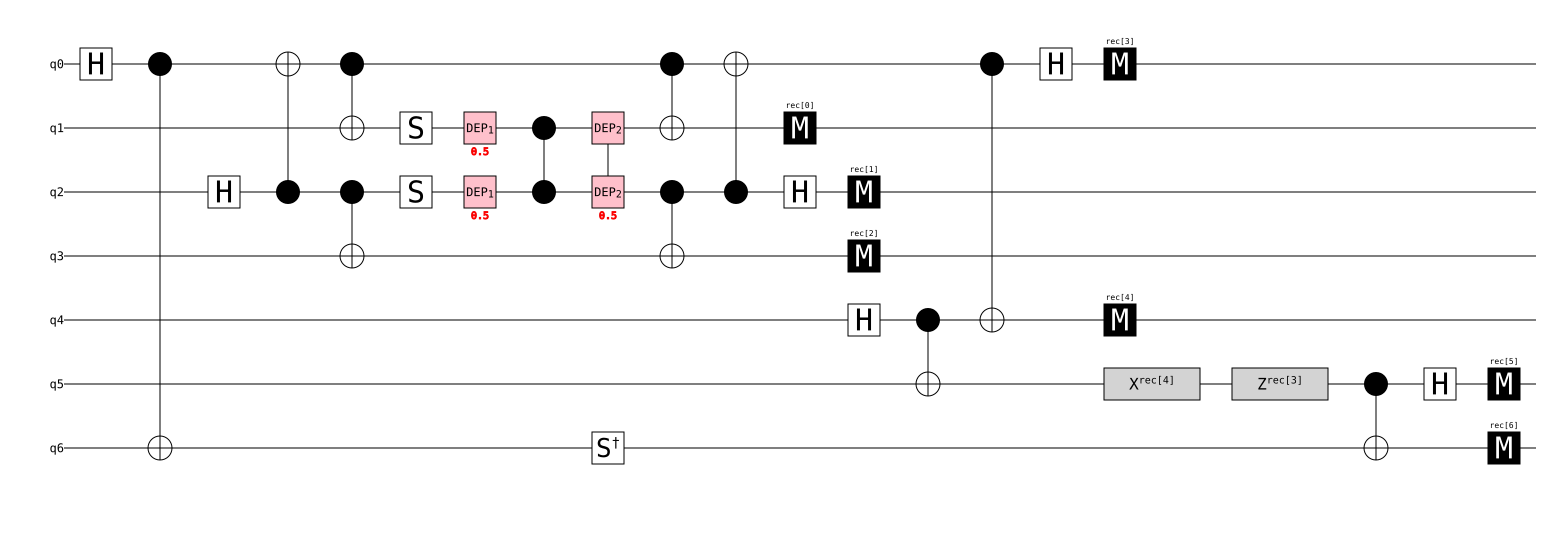

In [73]:

circuit = stim.Circuit()

# Create a Bell pair between the input and reference qubit.
circuit.append("H", [0])
circuit.append("CNOT", [0, 6])

# Encoder.
circuit.append("H", [2])
circuit.append("CNOT", [2, 0])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 3])

# Logical S gate with errors.
circuit.append("S", [1, 2])
circuit.append("DEPOLARIZE1", [1, 2], p)
circuit.append("CZ", [1, 2])
circuit.append("DEPOLARIZE2", [1, 2], p)

# S_dag gate on the reference qubit.
circuit.append("S_DAG", [6])

# Decoder.
circuit.append("CNOT", [2, 3])
circuit.append("CNOT", [0, 1])
circuit.append("CNOT", [2, 0])
circuit.append("H", [2])

# Stabilizer measurements via the decoded ancillas.
# Qubit 1: Z0 Z1
# Qubit 2: X0 X1 X2 X3
# Qubit 3: Z2 Z3
# All three outcomes should be 0 in the absence of errors.
circuit.append("M", [1, 2, 3])

# Create the Bell pair for teleportation.
circuit.append("H", [4])
circuit.append("CNOT", [4, 5])

# Bell-basis measurement for teleportation.
circuit.append("CNOT", [0, 4])
circuit.append("H", [0])
circuit.append("M", [0, 4])

# Teleportation corrections.
circuit.append("CX", [stim.target_rec(-1), 5])
circuit.append("CZ", [stim.target_rec(-2), 5])

# Final Bell-basis measurement of output and reference.
circuit.append("CNOT", [5, 6])
circuit.append("H", [5])
circuit.append("M", [5, 6])

print(repr(circuit))
circuit.diagram("timeline-svg")

In [74]:
#Sampling the circuit wuith encoding and decoding with errors and stabilizer measurements
sampler = circuit.compile_sampler()
print(sampler.sample(shots=10))

[[ True False  True False  True False  True]
 [False  True False  True False False False]
 [ True  True False False  True  True False]
 [False  True  True  True  True  True  True]
 [ True False  True False False False  True]
 [ True  True False  True False  True False]
 [False False False  True  True False False]
 [ True  True False False  True False False]
 [False  True  True  True False  True  True]
 [ True  True False False False False False]]


In [83]:
#Sampling and keeping only the accepted shots (where all stabilizer measurements are 0) and the final Bell outcomes
samples = circuit.compile_sampler().sample(shots=10_000)

accepted = ~samples[:, :3].any(axis=1)
bell_results = samples[accepted, 5:7]
efficiency = accepted.sum() / len(samples)
fidelity = (bell_results == [0, 0]).sum() / len(accepted)

print("Error rate:", p)
print("Total shots:", len(samples))
print("Accepted shots:", accepted.sum())
print("Efficiency:", efficiency)
print("Fidelity:", fidelity)
print("Final Bell outcomes:", bell_results)


Error rate: 0.999
Total shots: 10000
Accepted shots: 1202
Efficiency: 0.1202
Fidelity: 0.1756
Final Bell outcomes: [[ True False]
 [False False]
 [False False]
 ...
 [False False]
 [False False]
 [ True False]]


In [79]:
import numpy as np
import matplotlib.pyplot as plt

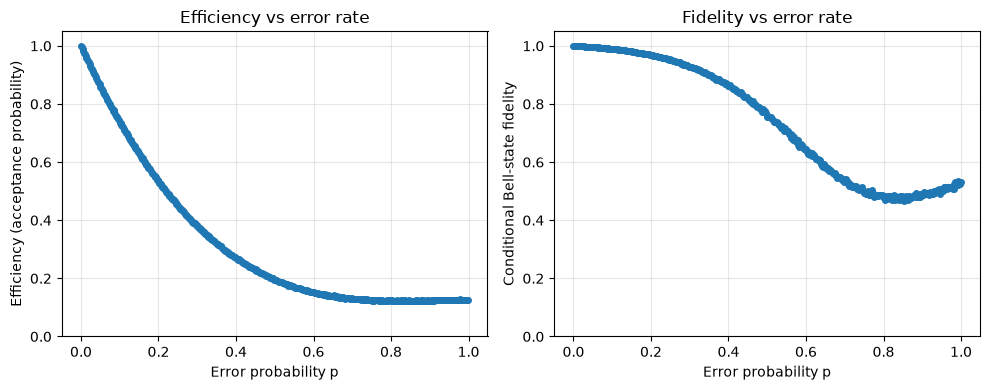

In [85]:

def make_circuit(p):
    return stim.Circuit(f"""
        # Initial Bell pair.
        H 0
        CX 0 6

        # Encoder.
        H 2
        CX 2 0 0 1 2 3

        # Noisy logical S.
        S 1 2
        DEPOLARIZE1({p}) 1 2
        CZ 1 2
        DEPOLARIZE2({p}) 1 2

        # Reference S.
        S 6

        # Decoder and syndrome measurements.
        CX 2 3 0 1 2 0
        H 2
        M 1 2 3

        # Teleportation.
        H 4
        CX 4 5 0 4
        H 0
        M 0 4
        CX rec[-1] 5
        CZ rec[-2] 5

        # Final Bell measurement.
        CX 5 6
        H 5
        M 5 6
    """)


error_rates = np.linspace(0, 0.999, 500)
shots = 100_000
expected_bell = np.array([1, 0])

efficiencies = []
fidelities = []

for p in error_rates:
    circuit = make_circuit(float(p))
    samples = circuit.compile_sampler().sample(shots=shots)

    # Accept shots with syndrome 000.
    accepted = ~samples[:, :3].any(axis=1)
    bell_results = samples[accepted, 5:7]

    efficiency = accepted.mean()

    # Fidelity conditional on acceptance.
    fidelity = (
        np.all(bell_results == expected_bell, axis=1).mean()
        if len(bell_results) > 0
        else np.nan
    )

    efficiencies.append(efficiency)
    fidelities.append(fidelity)


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(error_rates, efficiencies, "o-", markersize=4)
axes[0].set_ylabel("Efficiency (acceptance probability)")
axes[0].set_title("Efficiency vs error rate")

axes[1].plot(error_rates, fidelities, "o-", markersize=4)
axes[1].set_ylabel("Conditional Bell-state fidelity")
axes[1].set_title("Fidelity vs error rate")

for ax in axes:
    ax.set_xlabel("Error probability p")
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()